<p style="text-align:center; font-size: 28px;">AI in Health Technologies (2026)</p>
<p style="text-align:center; font-size: 28px;">Project: Source or clinical content?</p>
<p style="text-align:center; font-size: 20px;">Alexandra Dahlberg, Heidi Tarkiainen, Joonatan Syrjänen</p>

### Table of Contents

* [1. Introduction](#section_1)
* [2. Setup](#section_2)
* [3. Data](#section_3)
* [4. Embeddings](#section_4)
* [5. Pictures](#section_5)
    * [5.1. PCA](#section_5_1)
    * [5.2. t-SNE](#section_5_2)
    * [5.3. UMAP](#section_5_3)
    * [5.4. Notes vs imaging texts](#section_5_4)
* [6. Q1: Do the notes separate by text type?](#section_6)
* [7. Classifiers](#section_7)
* [8. Q2: Does the picture predict how hard a diagnosis is?](#section_8)
* [9. Seeds and UMAP settings](#section_9)
* [10. Note type and diagnosis mixed up?](#section_10)
* [11. FinBERT layers (Acamedic only)](#section_11)
* [12. Clinical review](#section_12)
* [13. Package versions](#section_13)

## 1. Introduction <a class="anchor" id="section_1"></a>

A language model turns each clinical note into an embedding, a long list of numbers. PCA, t-SNE and UMAP squeeze these into a 2-D picture where similar notes end up close together. In earlier work on lung imaging reports, our group saw that these pictures split clearly by note type but not by cancer diagnosis. That worries us: if a model can tell what kind of note it is reading, anything trained on top of it might learn the note type instead of the disease.

So we looked at vascular surgery notes from one EHR (Apotti) and asked two questions:

- **Q1:** Do the notes separate by text type (note type, specialty, year) rather than by what they say?
- **Q2:** Do they separate by diagnosis, and does the picture tell us how hard a diagnosis classifier will find the task?

We did not want to trust the pictures alone, so we checked each one with numbers in the full embedding space.

We built everything on synthetic notes first, with structure planted on purpose, and then ran the same notebook on the real notes in HUS Acamedic. Only numbers and figures left Acamedic, never text.

**Running it.** On the synthetic data the notebook runs from top to bottom without Ollama, because the embeddings are saved in `embeddings/`. In Colab, the first code cell gets the repo and installs `umap-learn`.

## 2. Setup <a class="anchor" id="section_2"></a>

In [1]:
# Packages
import os
import sys
import warnings
from importlib.metadata import version
warnings.filterwarnings("ignore", category=FutureWarning) # Notices about future package versions, they did not change the results

# In Colab we first had to get the repo and umap-learn
if "google.colab" in sys.modules:
    os.system("pip install umap-learn")
    os.system("git clone https://github.com/joonatansyrjanen/medical-text-umap")
    os.chdir("medical-text-umap")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy import stats

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score, silhouette_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import NearestNeighbors
import umap # pip install umap-learn

import torch
from torch import nn
from transformers import AutoTokenizer, AutoModel

In [2]:
# Synthetic data here, real data in Acamedic
data_source = "synthetic" # We changed this to "real" in Acamedic

if data_source == "synthetic":
    data_folder = "mock_data"
else:
    data_folder = "/path/to/acamedic/export"

# Embedding model, run through Ollama
model_name = "bge-m3"
ollama_url = "http://localhost:11434" # In Acamedic this was the address of the Azure ML compute
max_tokens = 8192 # BGE-M3 reads up to 8192 tokens, but Ollama cuts at 2048 unless we tell it otherwise

# FinBERT, only in Acamedic where we had it
run_finbert = False
finbert_path = "TurkuNLP/bert-base-finnish-cased-v1"
main_layer = 12 # We decided beforehand to use the last layer, the others are only for comparison

# Settings we fixed before looking at the real data
seed = 42
k = 15 # Neighbours in the kNN agreement
min_characters = 40 # Shorter notes were dropped
min_patients_per_code = 10 # Rarer ICD codes were left out of the diagnosis analysis
number_of_folds = 5 # Cross-validation folds, grouped by patient
checkpoint_epochs = [10, 25, 50, 100, 200, 500, 1000]
length_checkpoints = checkpoint_epochs + [2000, 5000, 10000, 20000] # Length alone learned more slowly
learning_rate = 0.001 # Constant in both epoch selection and refitting
weight_decay = 0.0001 # Keeps the classifier weights small
hidden_units = 256 # Size of the MLP hidden layer
tfidf_words = 5000 # Most common words kept for the TF-IDF baseline
device = "cuda" if torch.cuda.is_available() else "cpu" # The classifiers ran on the GPU when there was one
seeds = [0, 1, 2, 3, 4] # Random seeds for t-SNE and UMAP, seed 0 is the main picture
umap_neighbours = [5, 15, 50] # UMAP settings, 15 is the main picture
texts_per_table = 2500 # At most this many texts per table in the notes vs imaging picture, like Rami
number_of_clusters = 8 # For the clinical review, we set this after looking at the UMAP
notes_per_cluster = 5 # Notes the clinician read from each cluster

# Labels we coloured the pictures by
labels_to_check = ["note_type", "specialty", "year", "length_quartile", "diagnosis_group", "diagnosis_code"]

# Rami's colours from the lung imaging figures, plus a few lighter ones for labels with many classes
palette = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#72B7B2", "#EECA3B", "#B279A2", "#FF9DA6", "#9D755D", "#BAB0AC",
           "#9ECAE9", "#FFBF79", "#88D27A", "#83BCB6", "#FF9D98", "#D6A5C9"]
source_colours = {"apotti_kuvantaminen_lausunto": "#4C78A8", # Imaging reports, blue like Rami's
                  "apotti_kuvantaminen_tutkimus": "#F58518", # Imaging requests, orange
                  "apotti_potilaskertomus": "#54A24B"} # Patient record notes, green

# Figures and tables go here
results_folder = "results/" + model_name
os.makedirs(results_folder, exist_ok=True)

## 3. Data <a class="anchor" id="section_3"></a>

The texts are the free-text patient record entries (potilaskertomus). Each note got the main ICD-10 diagnosis of its care episode, joined through the episode ID.

Every note starts with a line giving the writer's role, name and time. Staff names alone give away the hospital, so we removed that line before embedding.

In [3]:
# Notes and diagnoses, both tables use ; as the separator
notes = pd.read_csv(data_folder + "/Apotti_potilaskertomus.csv", sep=";")
diagnoses = pd.read_csv(data_folder + "/Apotti_diagnoosi.csv", sep=";")

# Main diagnosis of each care episode, joined to the notes through the episode ID
main_diagnoses = diagnoses[diagnoses["paadiagnoosi"] == True]
main_diagnoses = main_diagnoses.drop_duplicates(subset="shjakso_id") # A few episodes had the same code twice
notes = notes.merge(main_diagnoses[["shjakso_id", "diagnoosi_koodi"]], on="shjakso_id", how="left")

# Shorter English names for the columns we used
notes["note_id"] = notes["merkinta_id"]
notes["patient_id"] = notes["henkilotunnus"]
notes["note_type"] = notes["merkinta_valilehti_selite"] # E.g. Päivittäismerkintä
notes["specialty"] = notes["toimipiste_eala_selite"] # Specialty of the writing unit
notes["year"] = notes["merkinta_luonti_hetki"].str[:4] # E.g. 2023
notes["diagnosis_code"] = notes["diagnoosi_koodi"] # E.g. I70.2
notes["diagnosis_group"] = notes["diagnoosi_koodi"].str[:3] # E.g. I70

# The text without its first line (role, name and time)
notes["text"] = notes["merkinta_teksti"].str.split("\n", n=1).str[1]
notes["text"] = notes["text"].fillna("") # Notes with nothing after the first line

Very short notes, like "Uusi aika annettu.", say almost nothing, so we dropped them. Next we split note length into four equal groups. That way we could see whether a picture just sorts short notes from long ones (the proposal feedback suggested length as a surface baseline). ICD codes with fewer than 10 patients were left out of the diagnosis analysis, but their notes stayed in.

In [4]:
# Very short notes dropped
notes["characters"] = notes["text"].str.len()
print("Notes shorter than %d characters dropped: %d"
      % (min_characters, np.sum(notes["characters"] < min_characters)))
notes = notes[notes["characters"] >= min_characters]
notes = notes.reset_index(drop=True) # Row n of notes is row n of the embeddings

# Note length in four equal groups
notes["length_quartile"] = pd.qcut(notes["characters"], 4, labels=["Q1 shortest", "Q2", "Q3", "Q4 longest"]).astype(str)

# Rare ICD codes and groups left out of the diagnosis analysis
patients_per_code = notes.groupby("diagnosis_code")["patient_id"].nunique()
rare_codes = patients_per_code[patients_per_code < min_patients_per_code].index
notes.loc[notes["diagnosis_code"].isin(rare_codes), "diagnosis_code"] = np.nan

patients_per_group = notes.groupby("diagnosis_group")["patient_id"].nunique()
rare_groups = patients_per_group[patients_per_group < min_patients_per_code].index
notes.loc[notes["diagnosis_group"].isin(rare_groups), "diagnosis_group"] = np.nan

# Most notes from one patient, needed for the kNN agreement in Section 6
most_notes_per_patient = notes.groupby("patient_id").size().max()

# Numbers for Table 1
print("Notes: %d"
      % notes.shape[0])
print("Patients: %d"
      % notes["patient_id"].nunique())
print("ICD-10 codes kept: %d"
      % notes["diagnosis_code"].nunique())
print("Most notes from one patient: %d"
      % most_notes_per_patient)
for label in ["note_type", "specialty", "year", "diagnosis_group"]:
    print()
    print(notes[label].value_counts())

Notes shorter than 40 characters dropped: 585
Notes: 10443
Patients: 593
ICD-10 codes kept: 12
Most notes from one patient: 117

note_type
Hoitotyön merkintä    4309
Päivittäismerkintä    2258
Kuntoutus             1178
Poliklinikkakäynti     991
Puhelinkontakti        570
Leikkauskertomus       406
Konsultaatio           333
Loppuarvio             318
Sosiaalityö             80
Name: count, dtype: int64

specialty
Verisuonikirurgia    8852
Fysioterapia         1178
Anestesiologia        224
Infektiosairaudet      92
Sosiaalityö            80
Kardiologia            17
Name: count, dtype: int64

year
2023    2109
2020    1687
2022    1659
2024    1323
2025    1307
2019    1223
2021    1102
2026      33
Name: count, dtype: int64

diagnosis_group
I71    2994
R02    2276
I70    1772
I74    1011
E11     691
I65     680
I83     411
G45     282
R10      36
Name: count, dtype: int64


In the earlier lung work, notes and radiology reports ended up far apart in the pictures. To see the same thing in our data, we also took the imaging reports (lausunto) and imaging requests (tutkimus). As in Rami's figures, we used at most 2500 texts per table.

In [5]:
# Imaging reports and requests
reports_table = pd.read_csv(data_folder + "/Apotti_kuvantaminen_lausunto.csv", sep=";")
requests_table = pd.read_csv(data_folder + "/Apotti_kuvantaminen_tutkimus.csv", sep=";")

reports = pd.DataFrame({"text_id": reports_table["ac_numero"].astype(str) + "_lausunto",
                        "patient_id": reports_table["henkilotunnus"],
                        "source": "apotti_kuvantaminen_lausunto",
                        "text": reports_table["lausunto_teksti"]})
imaging_requests = pd.DataFrame({"text_id": requests_table["maarays_id"].astype(str) + "_pyynto",
                                 "patient_id": requests_table["henkilotunnus"],
                                 "source": "apotti_kuvantaminen_tutkimus",
                                 "text": requests_table["pyynto_teksti"]})

# At most texts_per_table from each table
if reports.shape[0] > texts_per_table:
    reports = reports.sample(n=texts_per_table, random_state=seed)
if imaging_requests.shape[0] > texts_per_table:
    imaging_requests = imaging_requests.sample(n=texts_per_table, random_state=seed)

imaging = pd.concat([reports, imaging_requests], ignore_index=True)
imaging = imaging[imaging["text"].str.len() >= min_characters] # Same rule as for the notes
imaging = imaging.reset_index(drop=True)

print(imaging["source"].value_counts())

source
apotti_kuvantaminen_lausunto    900
apotti_kuvantaminen_tutkimus    900
Name: count, dtype: int64


## 4. Embeddings <a class="anchor" id="section_4"></a>

We used BGE-M3, a multilingual model that covers Finnish and reads up to 8192 tokens. We ran it through Ollama, both on our own computers and in Acamedic, so the same code worked in both places. Ollama gives one vector of 1024 numbers per note.

Embedding takes a while, so we saved the vectors in `embeddings/` and loaded them on later runs. To make them again, install Ollama, run `ollama pull bge-m3` in a terminal and delete the `.npy` file.

In [6]:
def embed(text):
    """Sends one text to Ollama and gets back its embedding and the number of tokens it read."""
    response = requests.post(ollama_url + "/api/embed", json={
        "model": model_name,
        "input": text,
        "options": {"num_ctx": max_tokens, "num_batch": max_tokens}, # Without these Ollama cut every text at 2048 tokens
    })
    answer = response.json()
    return answer["embeddings"][0], answer["prompt_eval_count"]


# Notes, embedded once and then loaded from the file
notes_file = "embeddings/" + model_name + "_no_header.npy"
notes_tokens_file = "embeddings/" + model_name + "_no_header_labels.csv"

if os.path.exists(notes_file):
    embeddings = np.load(notes_file)
    saved = pd.read_csv(notes_tokens_file)
    assert saved["note_id"].tolist() == notes["note_id"].tolist(), "The saved embeddings are for other notes, delete the file and embed again"
    notes["tokens"] = saved["tokens"]
    print("Loaded %d embeddings from %s"
          % (embeddings.shape[0], notes_file))
else:
    # First we checked that Ollama really read 8192 tokens, otherwise long notes get cut without any warning
    vector, tokens_read = embed("Potilas voi hyvin. " * 5000)
    print("Tokens read from a very long text: %d (should be %d)"
          % (tokens_read, max_tokens))

    # Then every note, one at a time
    embeddings = []
    tokens = []
    for text in notes["text"]:
        vector, tokens_read = embed(text)
        embeddings.append(vector)
        tokens.append(tokens_read)
        if len(embeddings) % 1000 == 0:
            print("Embedded %d of %d notes"
                  % (len(embeddings), notes.shape[0]))
    embeddings = np.array(embeddings)
    notes["tokens"] = tokens
    np.save(notes_file, embeddings)
    notes[["note_id", "tokens"]].to_csv(notes_tokens_file, index=False)

print("Embeddings: %d notes, %d numbers each"
      % embeddings.shape)

Loaded 10443 embeddings from embeddings/bge-m3_no_header.npy
Embeddings: 10443 notes, 1024 numbers each


In [7]:
# Imaging reports and requests, the same way
imaging_file = "embeddings/" + model_name + "_imaging.npy"
imaging_tokens_file = "embeddings/" + model_name + "_imaging_labels.csv"

if os.path.exists(imaging_file):
    imaging_embeddings = np.load(imaging_file)
    saved = pd.read_csv(imaging_tokens_file)
    assert saved["text_id"].tolist() == imaging["text_id"].tolist(), "The saved embeddings are for other texts, delete the file and embed again"
    print("Loaded %d embeddings from %s"
          % (imaging_embeddings.shape[0], imaging_file))
else:
    imaging_embeddings = []
    tokens = []
    for text in imaging["text"]:
        vector, tokens_read = embed(text)
        imaging_embeddings.append(vector)
        tokens.append(tokens_read)
    imaging_embeddings = np.array(imaging_embeddings)
    imaging["tokens"] = tokens
    np.save(imaging_file, imaging_embeddings)
    imaging[["text_id", "tokens"]].to_csv(imaging_tokens_file, index=False)
    print("Embedded %d imaging texts"
          % imaging_embeddings.shape[0])

Loaded 1800 embeddings from embeddings/bge-m3_imaging.npy


The feedback asked how we handled notes over 512 tokens. BGE-M3 reads up to 8192 tokens, so with BGE-M3 nothing was cut. FinBERT (Section 11) reads only 512, so there a longer note was cut to its first 512 tokens.

In [8]:
# How long the notes were, counted with the BGE-M3 tokenizer
print("Longest note: %d tokens"
      % notes["tokens"].max())
print("Notes cut at %d tokens by BGE-M3: %d"
      % (max_tokens, np.sum(notes["tokens"] >= max_tokens)))
print("Notes over 512 tokens, which FinBERT would cut: %d (%.1f %%)"
      % (np.sum(notes["tokens"] > 512), 100 * np.mean(notes["tokens"] > 512)))

Longest note: 1042 tokens
Notes cut at 8192 tokens by BGE-M3: 0
Notes over 512 tokens, which FinBERT would cut: 319 (3.1 %)


## 5. Pictures <a class="anchor" id="section_5"></a>

We made the pictures with PCA, t-SNE and UMAP and coloured each one by every label. PCA is the simple linear one. t-SNE and UMAP try to keep notes that are close in the full space close in the picture too. Their axes have no units, and the distance between two far-apart clusters means very little.

We drew all pictures the same way as Rami's lung figures: his colours, the biggest class first and the number of notes in the legend. This function draws one picture.

In [9]:
def plot_by_label(ax, points, labels, label_name, title):
    """Draws the 2-D points as a square picture, one colour per class, like Rami's figures."""
    labels = pd.Series(list(labels)) # Plain 0, 1, 2... index so it matches the rows of points

    # Text sources keep Rami's colours, other labels get his palette with the biggest class first
    if label_name == "source":
        classes = [name for name in source_colours if name in labels.values]
        colours = source_colours
    else:
        classes = list(labels.value_counts().index)
        if label_name in ["year", "length_quartile"]:
            classes = sorted(classes) # In order rather than by size
        colours = {}
        for index in range(len(classes)):
            colours[classes[index]] = palette[index % len(palette)]

    # Notes without a label (rare ICD codes) in light grey underneath
    missing = labels.isnull().to_numpy()
    if missing.sum() > 0:
        ax.scatter(points[missing, 0], points[missing, 1], s=4, color="#DDDDDD", label="no label (%d)" % missing.sum())

    # Then one class at a time, with the number of notes in the legend
    for name in classes:
        in_class = (labels == name).to_numpy()
        ax.scatter(points[in_class, 0], points[in_class, 1], s=4, alpha=0.7, color=colours[name],
                   label="%s (%d)" % (name, in_class.sum()))

    ax.set_title(title)
    ax.set_xticks([]) # No units on these axes
    ax.set_yticks([])
    ax.set_box_aspect(1) # Square picture
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, frameon=False, markerscale=3)

### 5.1. PCA <a class="anchor" id="section_5_1"></a>

Variance explained by the two components: 23.4 %


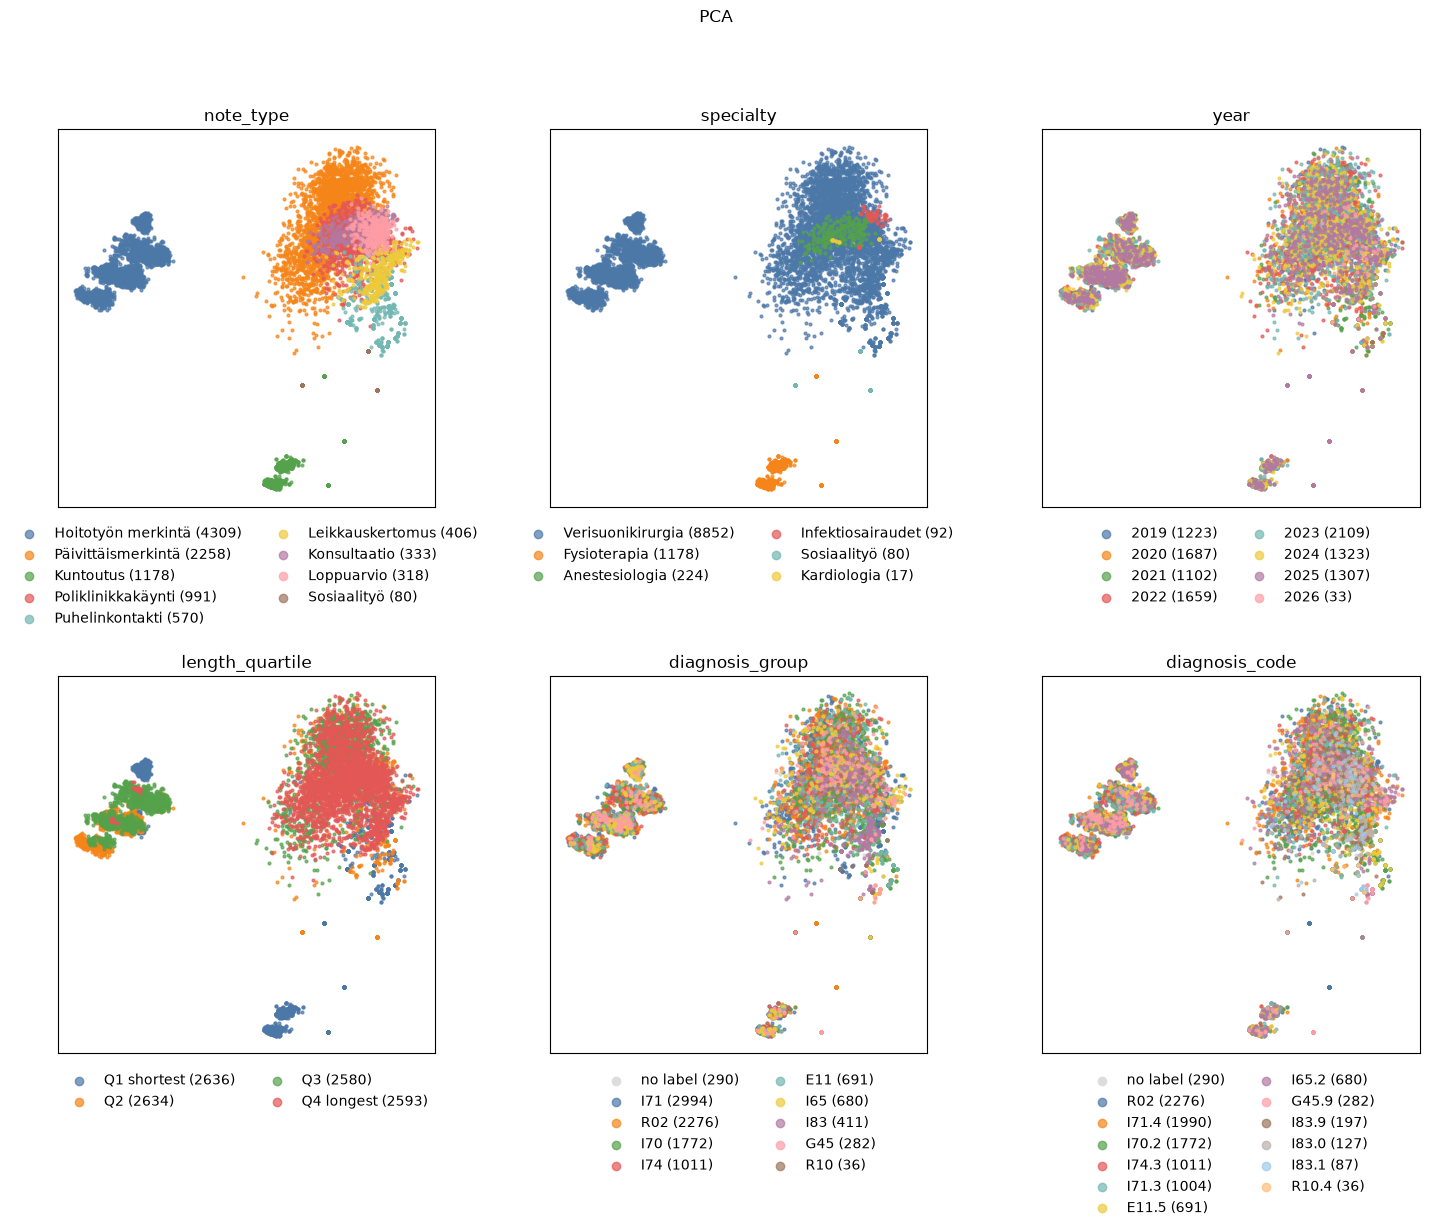

In [10]:
# PCA to 2-D
pca = PCA(n_components=2)
pca_points = pca.fit_transform(embeddings)
print("Variance explained by the two components: %.1f %%"
      % (100 * np.sum(pca.explained_variance_ratio_)))

# One picture per label
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.subplots_adjust(hspace=0.45) # Room for the legends between the rows
for index in range(len(labels_to_check)):
    label = labels_to_check[index]
    plot_by_label(axes.flat[index], pca_points, notes[label], label, label)
fig.suptitle("PCA")
fig.savefig(results_folder + "/pca.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.2. t-SNE <a class="anchor" id="section_5_2"></a>

We ran t-SNE with five random seeds (cosine distance, perplexity 30, starting from the PCA layout). Seed 0 is the picture we show; the other seeds come back in Section 9.

t-SNE seed 0 done
t-SNE seed 1 done
t-SNE seed 2 done
t-SNE seed 3 done
t-SNE seed 4 done


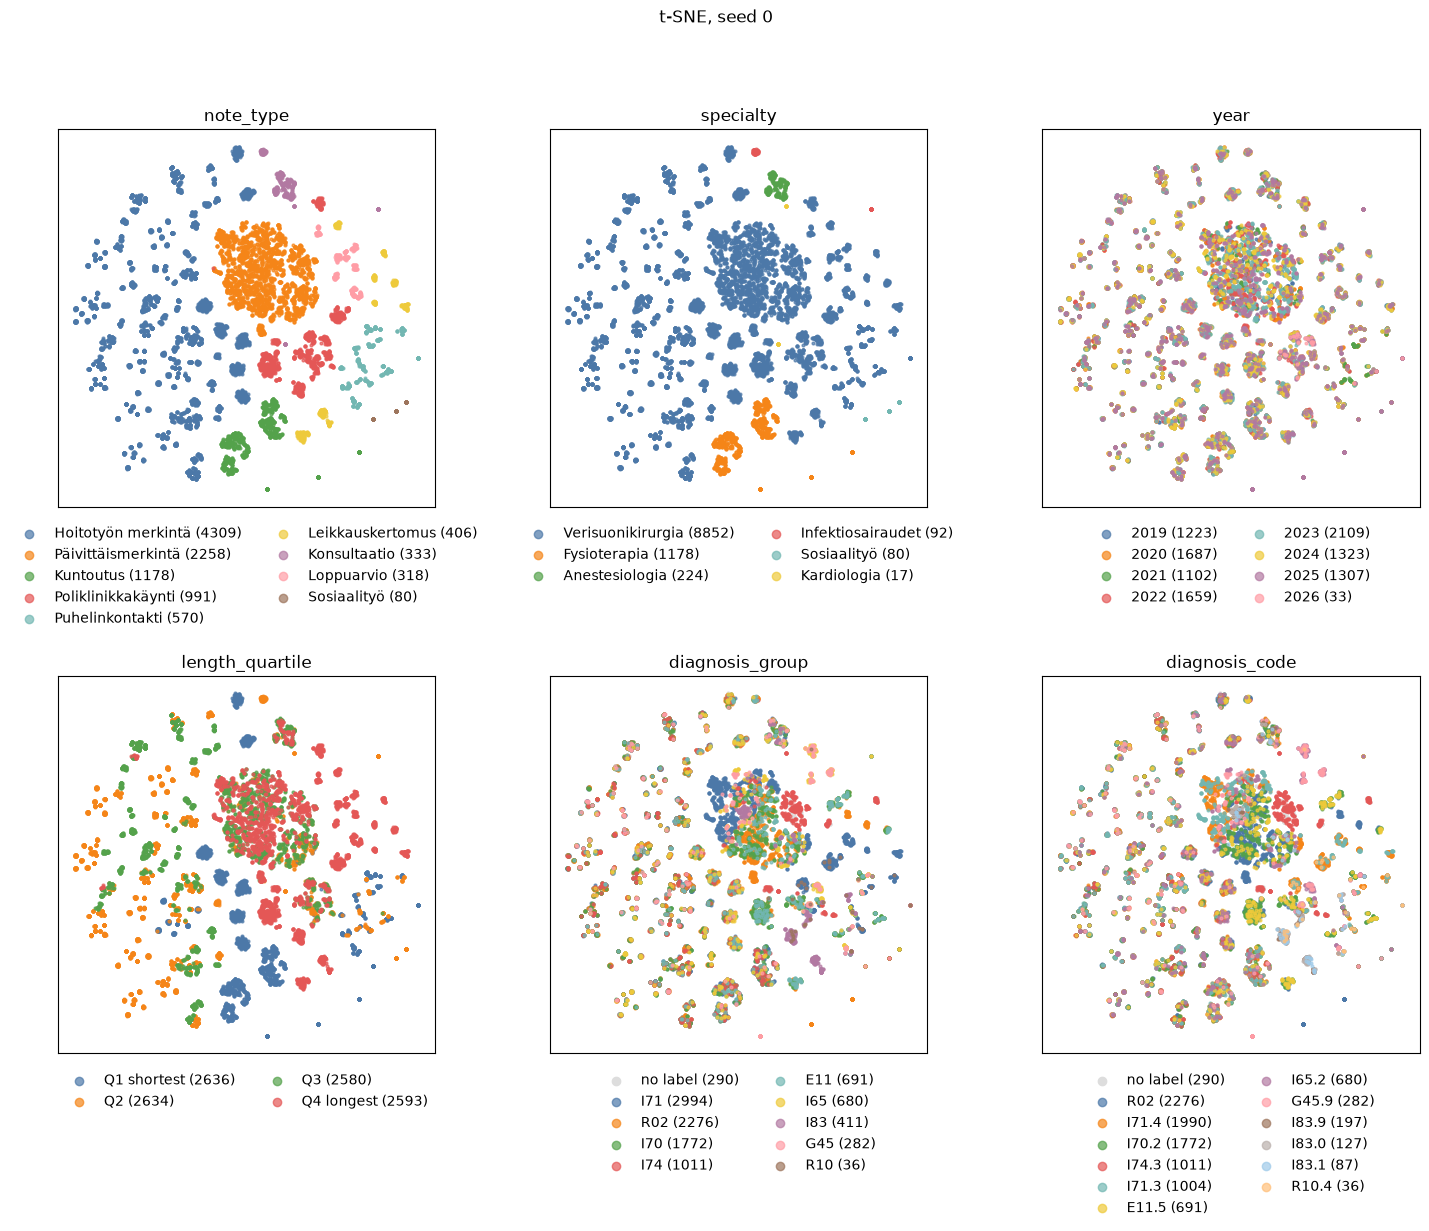

In [11]:
# t-SNE, one run per seed
tsne_points = {}
for projection_seed in seeds:
    tsne = TSNE(metric="cosine", perplexity=30, init="pca", random_state=projection_seed)
    tsne_points[projection_seed] = tsne.fit_transform(embeddings)
    print("t-SNE seed %d done"
          % projection_seed)

# One picture per label, seed 0
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.subplots_adjust(hspace=0.45) # Room for the legends between the rows
for index in range(len(labels_to_check)):
    label = labels_to_check[index]
    plot_by_label(axes.flat[index], tsne_points[0], notes[label], label, label)
fig.suptitle("t-SNE, seed 0")
fig.savefig(results_folder + "/tsne.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.3. UMAP <a class="anchor" id="section_5_3"></a>

UMAP ran with cosine distance and `min_dist` 0.1, starting from the PCA layout. The default start failed on the exact duplicate notes that copy-paste creates. We tried `n_neighbors` 5, 15 and 50 with the same five seeds; `n_neighbors` 15 with seed 0 is the main picture.

UMAP n_neighbors 5 done
UMAP n_neighbors 15 done
UMAP n_neighbors 50 done


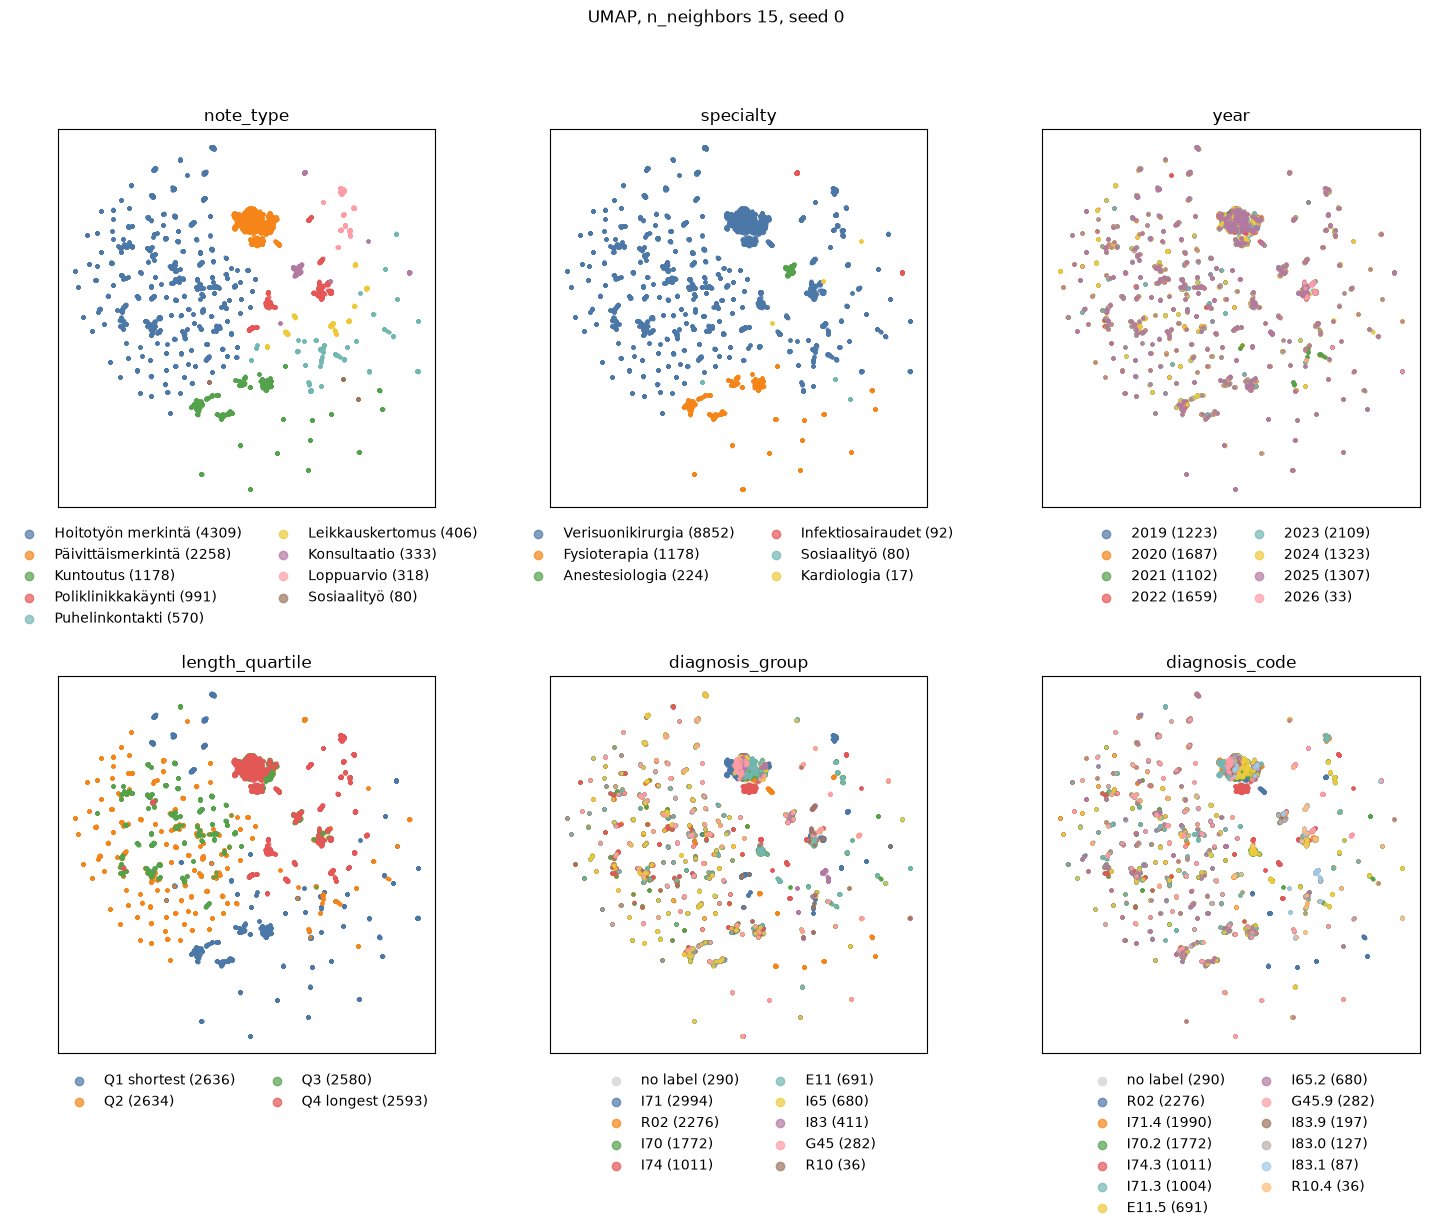

In [12]:
# UMAP, every setting with every seed
umap_points = {}
for n_neighbors in umap_neighbours:
    for projection_seed in seeds:
        reducer = umap.UMAP(n_neighbors=n_neighbors, min_dist=0.1, metric="cosine", init="pca", random_state=projection_seed, n_jobs=1) # One thread, because we fixed the seed
        umap_points[(n_neighbors, projection_seed)] = reducer.fit_transform(embeddings)
    print("UMAP n_neighbors %d done"
          % n_neighbors)
main_umap = umap_points[(15, 0)] # The main picture

# One picture per label
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.subplots_adjust(hspace=0.45) # Room for the legends between the rows
for index in range(len(labels_to_check)):
    label = labels_to_check[index]
    plot_by_label(axes.flat[index], main_umap, notes[label], label, label)
fig.suptitle("UMAP, n_neighbors 15, seed 0")
fig.savefig(results_folder + "/umap.png", dpi=150, bbox_inches="tight")
plt.show()

# The coordinates of the main pictures, these were allowed to leave Acamedic
coordinates = pd.DataFrame({"note_id": notes["note_id"],
                            "pca_x": pca_points[:, 0], "pca_y": pca_points[:, 1],
                            "tsne_x": tsne_points[0][:, 0], "tsne_y": tsne_points[0][:, 1],
                            "umap_x": main_umap[:, 0], "umap_y": main_umap[:, 1]})
coordinates.to_csv(results_folder + "/coordinates.csv", index=False)

### 5.4. Notes vs imaging texts <a class="anchor" id="section_5_4"></a>

The same picture as Rami's lung imaging figure, but inside one EHR: patient record notes, imaging reports and imaging requests embedded with the same model, in his colours. We took 2500 random notes, so that the notes did not swamp the imaging texts.

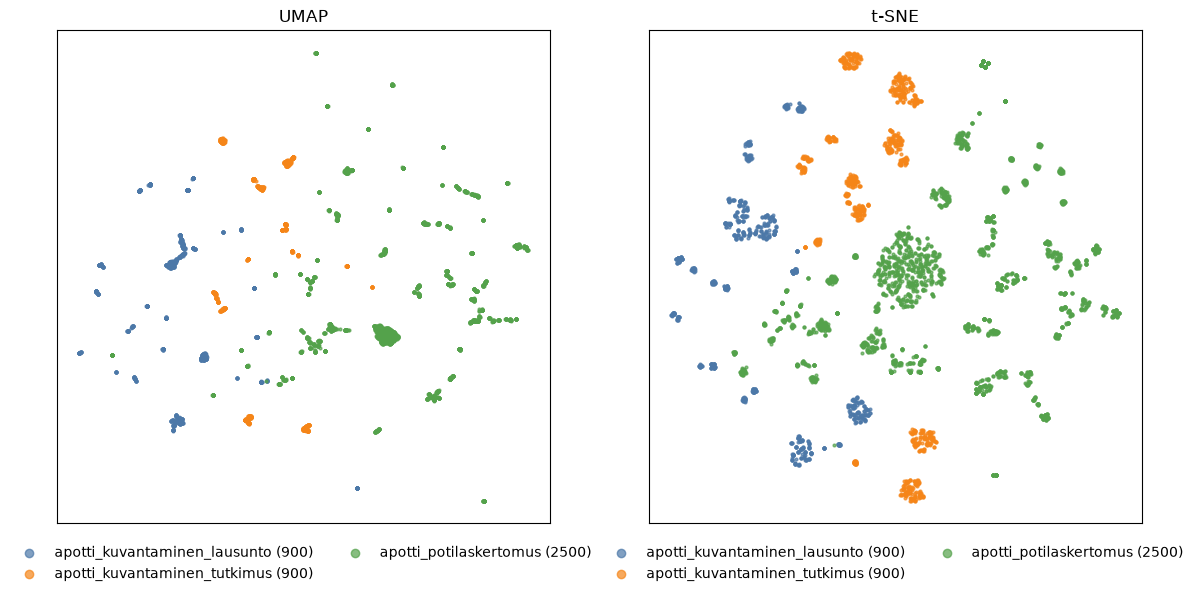

In [13]:
# 2500 random notes and the imaging texts together
note_sample = notes.sample(n=min(texts_per_table, notes.shape[0]), random_state=seed)
source_embeddings = np.vstack([embeddings[note_sample.index], imaging_embeddings])
source_labels = ["apotti_potilaskertomus"] * note_sample.shape[0] + imaging["source"].tolist()
source_patients = note_sample["patient_id"].tolist() + imaging["patient_id"].tolist()

# UMAP and t-SNE with the main settings
source_umap = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", init="pca", random_state=0, n_jobs=1).fit_transform(source_embeddings)
source_tsne = TSNE(metric="cosine", perplexity=30, init="pca", random_state=0).fit_transform(source_embeddings)

# Side by side, like Rami's figure
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
plot_by_label(axes[0], source_umap, source_labels, "source", "UMAP")
plot_by_label(axes[1], source_tsne, source_labels, "source", "t-SNE")
fig.savefig(results_folder + "/notes_vs_imaging.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Q1: Do the notes separate by text type? <a class="anchor" id="section_6"></a>

A picture can show clusters that are not really there, or hide ones that are. So next we wanted to check each picture with numbers, and we did it in the full 1024-number space as well as in 2-D.

**kNN label agreement.** For every note we looked at its 15 nearest notes and counted how many had the same label. We skipped notes from the same patient: copy-paste makes a patient's notes almost identical, and that would make every patient-level label, like the diagnosis, look separated. Big classes agree a lot just by chance, so we compared the agreement with the chance level, the sum of the squared class shares.

If the agreement is about the same in 2-D as in the full space, the picture is honest. If it is much lower, the picture hides structure.

In [14]:
def knn_agreement(points, labels, patients, metric):
    """For every note, the share of its k nearest notes from other patients that have the same label."""
    # Notes without a label (rare ICD codes) were left out
    has_label = pd.Series(list(labels)).notnull().to_numpy()
    points = points[has_label]
    labels = np.array(list(labels), dtype=object)[has_label]
    patients = np.array(list(patients))[has_label]

    # We asked for extra neighbours, because the same patient's notes are skipped
    number_of_neighbours = min(len(labels), k + most_notes_per_patient)
    nearest = NearestNeighbors(n_neighbors=number_of_neighbours, metric=metric)
    nearest.fit(points)
    distances, neighbours = nearest.kneighbors(points)

    agreement = np.zeros(len(labels))
    for n in range(len(labels)):
        other_patients = neighbours[n][patients[neighbours[n]] != patients[n]] # Skips the note itself and its patient
        agreement[n] = np.mean(labels[other_patients[:k]] == labels[n])
    return agreement, labels


def chance_level(labels):
    """Agreement we would get by chance: the sum of the squared class shares."""
    shares = pd.Series(labels).value_counts(normalize=True)
    return np.sum(shares ** 2)

In [15]:
# Agreement for every label, in the full space and in the three main pictures
rows = []
for label in labels_to_check:
    agreement_full, used_labels = knn_agreement(embeddings, notes[label], notes["patient_id"], "cosine")
    agreement_pca, used_labels = knn_agreement(pca_points, notes[label], notes["patient_id"], "euclidean")
    agreement_tsne, used_labels = knn_agreement(tsne_points[0], notes[label], notes["patient_id"], "euclidean")
    agreement_umap, used_labels = knn_agreement(main_umap, notes[label], notes["patient_id"], "euclidean")
    rows.append([label, chance_level(used_labels), np.mean(agreement_full),
                 np.mean(agreement_pca), np.mean(agreement_tsne), np.mean(agreement_umap)])

knn_table = pd.DataFrame(rows, columns=["label", "chance", "full", "pca", "tsne", "umap"])
knn_table.to_csv(results_folder + "/knn_agreement.csv", index=False)
knn_table.round(2)

,label,chance,full,pca,tsne,umap
0,note_type,0.25,1.00,0.85,1.00,1.00
1,specialty,0.73,1.00,0.96,1.00,1.00
2,year,0.15,0.15,0.14,0.15,0.15
3,length_quartile,0.25,0.85,0.68,0.85,0.82
4,diagnosis_group,0.19,0.42,0.25,0.42,0.41
5,diagnosis_code,0.15,0.34,0.20,0.34,0.33


In the synthetic data we wrote each note type in its own style on purpose. So if the pipeline works, note type should come out far above chance here, both in the full space and in the pictures.

Then the same check for the notes vs imaging texts from 5.4.

In [16]:
# Agreement for the text source, full space and the two pictures
agreement_full, used_labels = knn_agreement(source_embeddings, source_labels, source_patients, "cosine")
agreement_umap, used_labels = knn_agreement(source_umap, source_labels, source_patients, "euclidean")
agreement_tsne, used_labels = knn_agreement(source_tsne, source_labels, source_patients, "euclidean")
print("Notes vs imaging texts, chance %.2f: full space %.2f, UMAP %.2f, t-SNE %.2f"
      % (chance_level(used_labels), np.mean(agreement_full), np.mean(agreement_umap), np.mean(agreement_tsne)))

Notes vs imaging texts, chance 0.43: full space 1.00, UMAP 1.00, t-SNE 1.00


We also computed silhouette scores, as planned in the proposal. They go from -1 to 1, and around 0 means the classes overlap. Unlike the kNN agreement, they do not skip the same patient's notes.

In [17]:
# Silhouette for every label, full space and the three main pictures
rows = []
for label in labels_to_check:
    has_label = notes[label].notnull().to_numpy()
    labels = notes[label][has_label]
    rows.append([label,
                 silhouette_score(embeddings[has_label], labels, metric="cosine"),
                 silhouette_score(pca_points[has_label], labels),
                 silhouette_score(tsne_points[0][has_label], labels),
                 silhouette_score(main_umap[has_label], labels)])

silhouette_table = pd.DataFrame(rows, columns=["label", "full", "pca", "tsne", "umap"])
silhouette_table.to_csv(results_folder + "/silhouette.csv", index=False)
silhouette_table.round(2)

,label,full,pca,tsne,umap
0,note_type,0.33,0.38,0.19,0.28
1,specialty,0.17,-0.08,-0.13,-0.10
2,year,-0.03,-0.30,-0.20,-0.16
3,length_quartile,0.05,0.05,0.02,-0.01
4,diagnosis_group,-0.02,-0.28,-0.17,-0.15
5,diagnosis_code,-0.04,-0.30,-0.18,-0.18


## 7. Classifiers <a class="anchor" id="section_7"></a>

The episode's main diagnosis was predicted from each record. A linear classifier and a multilayer perceptron (MLP) with one hidden layer were applied to the full embeddings. Two linear baselines utilized note length and term frequency-inverse document frequency (TF-IDF). All four models were evaluated using the same five test folds grouped by patients.

Within each outer training fold, we considered five patient-grouped splits. A split was eligible if the fit set contained every diagnosis in the outer training fold and the validation set contained at least two diagnoses. For each eligible split, we counted distinct validation patients for every diagnosis in the outer training fold, counting a missing diagnosis as zero. We chose the split with the highest minimum count and kept the first split in a tie.

We scored seven checkpoints for the embedding and TF-IDF models and eleven for the length model. At each listed checkpoint, we calculated one-vs-rest AUROC (area under the receiver operating characteristic curve) for each diagnosis with both positive and negative validation notes. We gave each eligible diagnosis equal weight and selected the earliest checkpoint with the highest mean AUROC.

We saved the fit and validation cross-entropy, validation mean AUROC, and number of scored diagnoses at every checkpoint for every outer fold in `classifier_checkpoints.csv`. We show fold 1 below as a worked example.

We then refitted preprocessing and trained a new classifier on the full training fold for the selected number of epochs. On those training notes, we compared each model's cross-entropy with the loss of a predictor that used only the fold's diagnosis frequencies. We used the refitted classifier to predict diagnoses for the held-out test patients.

For each diagnosis, we pooled the held-out predictions from all five test folds and calculated one-vs-rest AUROC at the note level. This measures how often a note with that diagnosis receives a higher predicted probability for it than a note without it, counting ties as half. The two notes can come from different folds and be scored by different fitted models. We gave each diagnosis equal weight in the reported mean AUROC.

In [18]:
# Notes with a diagnosis code, the rare codes were already left out in Section 3
has_code = notes["diagnosis_code"].notnull().to_numpy()
classes = sorted(notes["diagnosis_code"][has_code].unique())
y = notes["diagnosis_code"][has_code].map({code: i for i, code in enumerate(classes)}).to_numpy()
groups = notes["patient_id"][has_code].to_numpy()

# The same folds for every model, grouped by patient and stratified by code
folds = list(StratifiedGroupKFold(n_splits=number_of_folds, shuffle=True, random_state=seed).split(np.zeros(len(y)), y, groups))

print("Notes: %d, patients: %d, ICD codes: %d"
      % (len(y), len(set(groups)), len(classes)))

# fit_local and val_local are positions in train. Each entry in train is a row number in the classifier data.
splits = []
validation_patients = {}
for fold, (train, test) in enumerate(folds, start=1):
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed + 1)
    train_codes = np.unique(y[train])
    coverage = []
    best_split = None
    best_minimum = -1  # Zero is possible when every eligible split lacks a diagnosis.
    for fit_local, val_local in splitter.split(train, y[train], groups[train]):
        fit, val = train[fit_local], train[val_local]
        fit_codes, val_codes = len(np.unique(y[fit])), len(np.unique(y[val]))
        if fit_codes != len(train_codes) or val_codes < 2:
            coverage.append((fit_codes, val_codes))
            continue
        patients = np.array([len(np.unique(groups[val][y[val] == code])) for code in range(len(classes))])
        minimum = patients[train_codes].min()
        if minimum > best_minimum:
            best_minimum = minimum
            best_split = (fit, val, train, test)
            validation_patients[fold] = patients
    if best_split is None:
        raise ValueError(f"Outer fold {fold} needs all {len(train_codes)} training diagnoses in fit and "
                         f"at least two in validation. Diagnosis counts (fit, validation) per candidate: {coverage}")
    splits.append(best_split)

print("Validation patients per ICD code in each outer fold")
print(pd.DataFrame(validation_patients, index=classes).to_string())

Notes: 10153, patients: 579, ICD codes: 12
Validation patients per ICD code in each outer fold
        1   2   3   4   5
E11.5   7   7  11   7   8
G45.9   6   6   5   5   4
I65.2  12  12   7  12   7
I70.2  21  22  23  25  24
I71.3   3   3   3   5   5
I71.4  14  16  16  16  16
I74.3   6   5   6   5   6
I83.0   5   5   5   5   5
I83.1   4   4   4   4   4
I83.9   7   7  10   7   9
R02    12  10  10   9   9
R10.4   3   2   3   3   3


In [19]:
def prepare_features(features, train, held_out, *, tfidf=False):
    """Fit the vocabulary (for text) and scaler using only this training split."""
    X_train, X_held_out = features[train], features[held_out]
    if tfidf:
        vectorizer = TfidfVectorizer(max_features=tfidf_words, dtype=np.float32)
        X_train = vectorizer.fit_transform(X_train).toarray()
        X_held_out = vectorizer.transform(X_held_out).toarray()

    mean = X_train.mean(axis=0)
    std = X_train.std(axis=0)
    std[std == 0] = 1
    return (torch.as_tensor((X_train - mean) / std, dtype=torch.float32, device=device),
            torch.as_tensor((X_held_out - mean) / std, dtype=torch.float32, device=device))


def train_checkpoints(X_train, targets, checkpoints, hidden=None):
    """Train once, yielding the current model after each requested epoch."""
    torch.manual_seed(seed)
    if hidden is None:
        model = nn.Linear(X_train.shape[1], len(classes))
    else:
        model = nn.Sequential(nn.Linear(X_train.shape[1], hidden), nn.ReLU(), nn.Linear(hidden, len(classes)))
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    previous_epoch = 0
    for epoch in checkpoints:
        model.train()
        for _ in range(previous_epoch, epoch):
            optimizer.zero_grad()
            loss = nn.functional.cross_entropy(model(X_train), targets)
            loss.backward()
            optimizer.step()
        model.eval()
        yield epoch, model
        previous_epoch = epoch


def select_epoch(X_fit, fit_targets, X_val, val_labels, checkpoints, hidden):
    """Score validation checkpoints and select the earliest with the highest macro AUROC."""
    counts = np.bincount(val_labels, minlength=len(classes))
    codes = np.flatnonzero((counts > 0) & (counts < len(val_labels)))
    if not len(codes):
        raise ValueError("Validation needs at least two diagnosis codes to compute AUROC.")
    val_targets = torch.as_tensor(val_labels, device=device)
    rows = []
    for epoch, model in train_checkpoints(X_fit, fit_targets, checkpoints, hidden):
        with torch.no_grad():
            train_loss = nn.functional.cross_entropy(model(X_fit), fit_targets).item()
            logits = model(X_val)
            val_loss = nn.functional.cross_entropy(logits, val_targets).item()
            scores = logits.softmax(dim=1).cpu().numpy()
        auc = np.mean([roc_auc_score(val_labels == code, scores[:, code]) for code in codes])
        rows.append((epoch, train_loss, val_loss, auc, len(codes)))
    history = pd.DataFrame(rows, columns=["epoch", "training_loss", "validation_loss", "macro_auroc", "codes"])
    return int(history.loc[history["macro_auroc"].idxmax(), "epoch"]), history

In [20]:
def cross_validate(name, features, checkpoints, *, hidden=None, tfidf=False):
    """Return test predictions, selected epochs, refit losses and checkpoint histories for all folds."""
    predictions = np.empty((len(y), len(classes)))
    selected = []
    refit_losses = []
    histories = []
    for fold, (fit, val, train, test) in enumerate(splits, start=1):
        X_fit, X_val = prepare_features(features, fit, val, tfidf=tfidf)
        epoch, history = select_epoch(X_fit, torch.as_tensor(y[fit], device=device),
                                      X_val, y[val], checkpoints, hidden)
        selected.append(epoch)
        histories.append(history.assign(model=name, fold=fold))
        if fold == 1:
            print(name, "on validation fold 1")
            print(history.round(4).to_string(index=False))
        del X_fit, X_val

        X_train, X_test = prepare_features(features, train, test, tfidf=tfidf)
        targets = torch.as_tensor(y[train], device=device)
        for _, model in train_checkpoints(X_train, targets, [epoch], hidden):
            with torch.no_grad():
                refit_losses.append(nn.functional.cross_entropy(model(X_train), targets).item())
                predictions[test] = model(X_test).softmax(dim=1).cpu().numpy()
        del X_train, X_test
    return predictions, selected, refit_losses, histories


lengths = np.log(notes.loc[has_code, ["characters", "tokens"]].to_numpy())
texts = notes.loc[has_code, "text"].to_numpy()
embedding_features = embeddings[has_code]
probabilities = {}
selected_epochs = {}
checkpoint_histories = []
# Entropy of the training counts is the loss from predicting those same frequencies for every note.
training_losses = {"Class frequency": [stats.entropy(np.bincount(y[train])) for train, _ in folds]}
for name, features, checkpoints, options in [
    ("Embeddings, linear", embedding_features, checkpoint_epochs, {}),
    ("Embeddings, MLP", embedding_features, checkpoint_epochs, {"hidden": hidden_units}),
    ("Length", lengths, length_checkpoints, {}),
    ("TF-IDF", texts, checkpoint_epochs, {"tfidf": True}),
]:
    predictions, epochs, losses, histories = cross_validate(name, features, checkpoints, **options)
    probabilities[name] = predictions
    selected_epochs[name] = epochs
    training_losses[name] = losses
    checkpoint_histories.extend(histories)

pd.concat(checkpoint_histories, ignore_index=True).to_csv(
    results_folder + "/classifier_checkpoints.csv", index=False,
    columns=["model", "fold", "epoch", "training_loss", "validation_loss", "macro_auroc", "codes"])

fold_index = pd.Index(range(1, len(splits) + 1), name="fold")
print("Selected epoch by outer fold")
print(pd.DataFrame(selected_epochs, index=fold_index))
print("Training cross-entropy after refitting each outer fold")
print(pd.DataFrame(training_losses, index=fold_index).round(4).to_string())

Embeddings, linear on validation fold 1
 epoch  training_loss  validation_loss  macro_auroc  codes
    10         1.8966           2.0096       0.7620     12
    25         1.5678           1.7448       0.8166     12
    50         1.3683           1.6063       0.8294     12
   100         1.2248           1.5128       0.8289     12
   200         1.1074           1.4677       0.8198     12
   500         0.9787           1.5120       0.8109     12
  1000         0.8881           1.6175       0.8045     12
Embeddings, MLP on validation fold 1
 epoch  training_loss  validation_loss  macro_auroc  codes
    10         1.3912           1.5242       0.8244     12
    25         1.1630           1.3883       0.8542     12
    50         1.0115           1.3878       0.8740     12
   100         0.7937           1.5408       0.8671     12
   200         0.5320           1.9369       0.8543     12
   500         0.2798           2.9106       0.8311     12
  1000         0.1840           3.7233

In [21]:
# One-vs-rest AUROC per ICD code at note level, from the test folds of all five splits together
rows = []
for index in range(len(classes)):
    is_code = y == index
    rows.append([classes[index]] + [roc_auc_score(is_code, probabilities[model][:, index]) for model in probabilities])

classifier_table = pd.DataFrame(rows, columns=["diagnosis_code"] + list(probabilities))
classifier_table.to_csv(results_folder + "/classifier_auroc.csv", index=False)

# Section 8 uses the linear model on the embeddings, the main classifier
classifier_table.rename(columns={"Embeddings, linear": "auroc"})[["diagnosis_code", "auroc"]].to_csv(
    results_folder + "/classifier_auroc_per_code.csv", index=False)

print("Mean AUROC over the codes:")
print(classifier_table.mean(numeric_only=True).round(3))
classifier_table.round(2)

Mean AUROC over the codes:
Embeddings, linear    0.833
Embeddings, MLP       0.866
Length                0.570
TF-IDF                0.814
dtype: float64


,diagnosis_code,"Embeddings, linear","Embeddings, MLP",Length,TF-IDF
0,E11.5,0.75,0.76,0.51,0.73
1,G45.9,0.81,0.84,0.51,0.81
2,I65.2,0.85,0.87,0.49,0.82
3,I70.2,0.79,0.80,0.50,0.76
4,I71.3,0.80,0.80,0.53,0.79
5,I71.4,0.83,0.84,0.53,0.82
6,I74.3,0.83,0.84,0.51,0.82
7,I83.0,0.98,0.99,0.73,0.98
8,I83.1,0.96,0.98,0.64,0.91
9,I83.9,0.99,0.99,0.71,0.98


## 8. Q2: Does the picture predict how hard a diagnosis is? <a class="anchor" id="section_8"></a>

Following the feedback, we used the finer ICD-10 codes instead of the four groups, so that the rank correlation has more than four points.

For each code we measured how separated it looks in the main UMAP, and put that next to how well the classifier did on it (AUROC from Section 7). We used agreement above chance, where 0 means no better than chance and 1 means all 15 neighbours have the same code. The plain agreement goes up just because a code is common, so on its own it would not work for comparing codes.

If the codes line up, the picture works as a cheap check of how hard a diagnosis task will be. With 10 or more codes we report the Spearman correlation; with fewer we only describe it.

In [22]:
# Agreement per ICD code, full space and main UMAP
agreement_full, codes = knn_agreement(embeddings, notes["diagnosis_code"], notes["patient_id"], "cosine")
agreement_umap, codes = knn_agreement(main_umap, notes["diagnosis_code"], notes["patient_id"], "euclidean")

rows = []
for code in sorted(set(codes)):
    is_code = codes == code
    chance = np.mean(is_code) # Share of notes with this code
    full_score = (np.mean(agreement_full[is_code]) - chance) / (1 - chance) # Agreement above chance
    umap_score = (np.mean(agreement_umap[is_code]) - chance) / (1 - chance)
    patients = notes.loc[notes["diagnosis_code"] == code, "patient_id"].nunique()
    rows.append([code, patients, np.sum(is_code), full_score, umap_score])

code_table = pd.DataFrame(rows, columns=["diagnosis_code", "patients", "notes", "full", "umap"])

# Classifier AUROC per code from Section 7, if it is there
auroc_file = results_folder + "/classifier_auroc_per_code.csv"
if os.path.exists(auroc_file):
    auroc_table = pd.read_csv(auroc_file)
    code_table = code_table.merge(auroc_table[["diagnosis_code", "auroc"]], on="diagnosis_code", how="left")
else:
    print("No classifier results yet, they come from Section 7")

code_table.to_csv(results_folder + "/per_code.csv", index=False)
code_table.round(2)

,diagnosis_code,patients,notes,full,umap,auroc
0,E11.5,56,691,0.07,0.06,0.75
1,G45.9,23,282,0.07,0.07,0.81
2,I65.2,58,680,0.27,0.25,0.85
3,I70.2,142,1772,0.18,0.16,0.79
4,I71.3,28,1004,0.12,0.11,0.80
5,I71.4,99,1990,0.28,0.26,0.83
6,I74.3,32,1011,0.31,0.32,0.83
7,I83.0,32,127,0.25,0.26,0.98
8,I83.1,23,87,0.16,0.15,0.96
9,I83.9,51,197,0.40,0.30,0.99


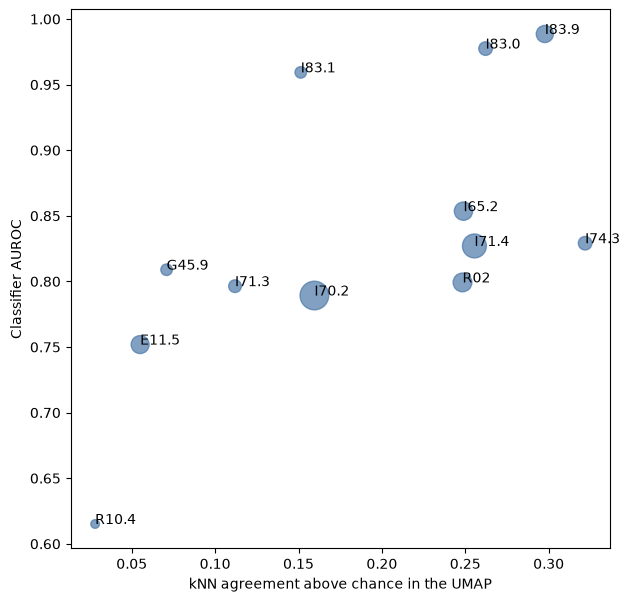

Spearman correlation 0.76, p = 0.00451, 12 codes


In [23]:
# Picture vs classifier, one dot per ICD code, dot size by the number of patients
if "auroc" in code_table.columns:
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.scatter(code_table["umap"], code_table["auroc"], s=3 * code_table["patients"], color=palette[0], alpha=0.7)
    for index in range(code_table.shape[0]):
        ax.annotate(code_table["diagnosis_code"][index], (code_table["umap"][index], code_table["auroc"][index]))
    ax.set_xlabel("kNN agreement above chance in the UMAP")
    ax.set_ylabel("Classifier AUROC")
    ax.set_box_aspect(1)
    fig.savefig(results_folder + "/picture_vs_classifier.png", dpi=300, bbox_inches="tight")
    plt.show()

    # Spearman correlation, only with 10 or more codes
    if code_table.shape[0] >= 10:
        correlation, p_value = stats.spearmanr(code_table["umap"], code_table["auroc"])
        print("Spearman correlation %.2f, p = %.3g, %d codes"
              % (correlation, p_value, code_table.shape[0]))
    else:
        print("Only %d codes, so we describe this instead of giving a correlation"
              % code_table.shape[0])

## 9. Seeds and UMAP settings <a class="anchor" id="section_9"></a>

We did not want any conclusion to rest on one picture. So we repeated the kNN agreement for note type (Q1) and diagnosis code (Q2) over every t-SNE seed and every UMAP setting and seed, and compared them with PCA and the full space.

In [24]:
# Agreement in every t-SNE and UMAP run
rows = []
for label in ["note_type", "diagnosis_code"]:
    for projection_seed in seeds:
        agreement, used_labels = knn_agreement(tsne_points[projection_seed], notes[label], notes["patient_id"], "euclidean")
        rows.append([label, "t-SNE", projection_seed, np.mean(agreement)])
    for n_neighbors in umap_neighbours:
        for projection_seed in seeds:
            agreement, used_labels = knn_agreement(umap_points[(n_neighbors, projection_seed)], notes[label], notes["patient_id"], "euclidean")
            rows.append([label, "UMAP n_neighbors %d" % n_neighbors, projection_seed, np.mean(agreement)])

seed_table = pd.DataFrame(rows, columns=["label", "projection", "seed", "agreement"])
seed_table.to_csv(results_folder + "/seeds_and_settings.csv", index=False)

# Mean, lowest and highest over the five seeds
print(seed_table.groupby(["label", "projection"])["agreement"].agg(["mean", "min", "max"]).round(2))

# PCA and the full space for comparison, from Section 6
print()
print(knn_table[knn_table["label"].isin(["note_type", "diagnosis_code"])][["label", "chance", "full", "pca"]].round(2))

                                    mean   min   max
label          projection                           
diagnosis_code UMAP n_neighbors 15  0.33  0.32  0.33
               UMAP n_neighbors 5   0.31  0.31  0.32
               UMAP n_neighbors 50  0.32  0.32  0.32
               t-SNE                0.34  0.34  0.34
note_type      UMAP n_neighbors 15  1.00  1.00  1.00
               UMAP n_neighbors 5   0.98  0.98  0.98
               UMAP n_neighbors 50  1.00  1.00  1.00
               t-SNE                1.00  1.00  1.00

            label  chance  full   pca
0       note_type    0.25  1.00  0.85
5  diagnosis_code    0.15  0.34  0.20


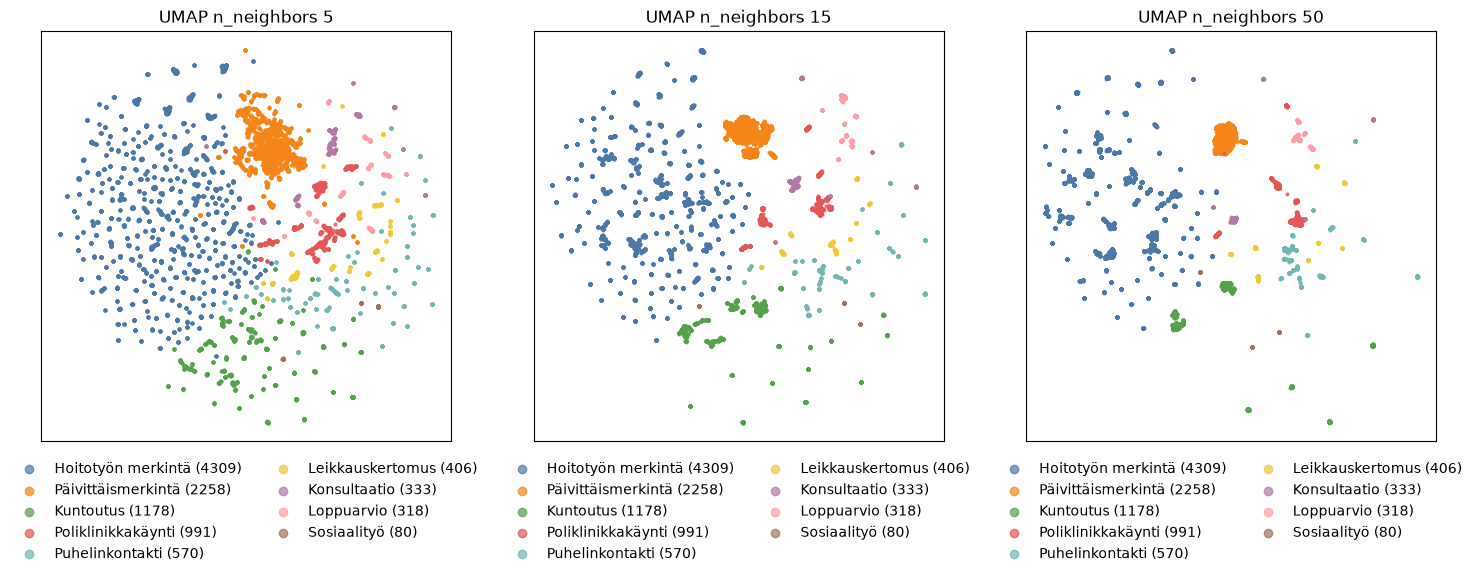

In [25]:
# The three UMAP settings side by side, coloured by note type
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for index in range(len(umap_neighbours)):
    n_neighbors = umap_neighbours[index]
    plot_by_label(axes[index], umap_points[(n_neighbors, 0)], notes["note_type"], "note_type", "UMAP n_neighbors %d" % n_neighbors)
fig.savefig(results_folder + "/umap_settings.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Note type and diagnosis mixed up? <a class="anchor" id="section_10"></a>

Some note types are much more common for some diagnoses, for example operation notes for patients who were operated on. A split by note type could then partly be a split by diagnosis, and the other way round. So we checked note type within each diagnosis group, and diagnosis code within each note type. We only used groups with at least 10 patients.

In [26]:
rows = []

# Note type within each diagnosis group
for group in sorted(notes["diagnosis_group"].dropna().unique()):
    in_group = (notes["diagnosis_group"] == group).to_numpy()
    if notes["patient_id"][in_group].nunique() < min_patients_per_code:
        continue
    agreement, used_labels = knn_agreement(embeddings[in_group], notes["note_type"][in_group], notes["patient_id"][in_group], "cosine")
    rows.append(["note type", "within " + group, len(used_labels), chance_level(used_labels), np.mean(agreement)])

# Diagnosis code within each note type
for note_type in sorted(notes["note_type"].unique()):
    in_type = (notes["note_type"] == note_type).to_numpy()
    if notes["patient_id"][in_type].nunique() < min_patients_per_code:
        continue
    agreement, used_labels = knn_agreement(embeddings[in_type], notes["diagnosis_code"][in_type], notes["patient_id"][in_type], "cosine")
    rows.append(["diagnosis code", "within " + note_type, len(used_labels), chance_level(used_labels), np.mean(agreement)])

mixed_table = pd.DataFrame(rows, columns=["label", "subset", "notes", "chance", "agreement"])
mixed_table.to_csv(results_folder + "/note_type_and_diagnosis.csv", index=False)
mixed_table.round(2)

,label,subset,notes,chance,agreement
0,note type,within E11,691,0.21,0.97
1,note type,within G45,282,0.21,0.92
2,note type,within I65,680,0.20,0.99
3,note type,within I70,1772,0.22,0.99
4,note type,within I71,2994,0.28,1.00
5,note type,within I74,1011,0.30,0.98
6,note type,within I83,411,0.24,1.00
7,note type,within R02,2276,0.31,0.99
8,note type,within R10,36,0.54,0.85
9,diagnosis code,within Hoitotyön merkintä,4194,0.17,0.17


## 11. FinBERT layers (Acamedic only) <a class="anchor" id="section_11"></a>

Through Ollama we only get the final vector of BGE-M3. To see in which layer the note type shows up, we also used FinBERT, which gives every layer. FinBERT reads at most 512 tokens, so we cut each note to its first 512 tokens, and we mean pooled the token vectors of each layer. We had decided beforehand that the last layer (12) is the main one; the others are only for comparison.

This only runs with `run_finbert = True`.

In [27]:
if run_finbert:
    tokenizer = AutoTokenizer.from_pretrained(finbert_path)
    finbert = AutoModel.from_pretrained(finbert_path, output_hidden_states=True) # Gives every layer, not just the last
    finbert.eval()

    # Mean of the token vectors in every layer, for every note
    layer_embeddings = np.zeros((13, notes.shape[0], 768)) # 13 layers (input and 1-12), 768 numbers each
    for n in range(notes.shape[0]):
        encoded = tokenizer(notes["text"][n], truncation=True, max_length=512, return_tensors="pt") # First 512 tokens
        with torch.no_grad():
            output = finbert(**encoded)
        for layer in range(13):
            layer_embeddings[layer, n] = output.hidden_states[layer][0].mean(dim=0).numpy()

    # kNN agreement for note type and diagnosis code in every layer
    note_type_agreement = []
    diagnosis_agreement = []
    for layer in range(13):
        agreement, used_labels = knn_agreement(layer_embeddings[layer], notes["note_type"], notes["patient_id"], "cosine")
        note_type_agreement.append(np.mean(agreement))
        agreement, used_labels = knn_agreement(layer_embeddings[layer], notes["diagnosis_code"], notes["patient_id"], "cosine")
        diagnosis_agreement.append(np.mean(agreement))

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.plot(range(13), note_type_agreement, color=palette[0], label="Note type")
    ax.plot(range(13), diagnosis_agreement, color=palette[1], label="Diagnosis code")
    ax.axvline(main_layer, linestyle="--", color="grey") # Main layer
    ax.set_xlabel("FinBERT layer")
    ax.set_ylabel("kNN agreement")
    ax.set_xticks(range(13))
    ax.set_box_aspect(1)
    ax.legend()
    fig.savefig(results_folder + "/finbert_layers.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("FinBERT not run")

FinBERT not run


## 12. Clinical review <a class="anchor" id="section_12"></a>

Finally we wanted to know what actually separates the clusters. We split the main UMAP into clusters with k-means, and a clinician on the team read five random notes from each cluster and wrote down what set them apart: template, structure or content. On the real data this happened inside Acamedic, and only these categories were reported, never the text.

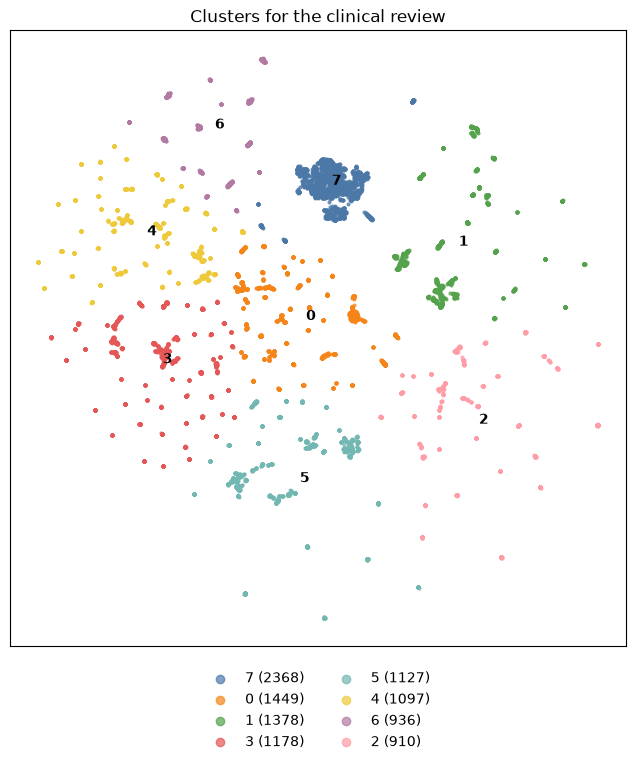

Cluster 0, Poliklinikkakäynti:
1. TULOSYY
Parantumaton haava vasemmassa jalassa, iskemiaepäily

2. TAUSTA
Verenpainetauti

3. LÄÄKITYS
asetyylisalisyylihappo 100 mg x 1 /vrk, rivaroksabaani 2,5 mg x 2 /vrk, atorvastatiini 40 mg x 1 /vrk, bisoprololi 5 mg x 1 /vrk

4. NYKYTILA
Lopettanut tupakoinnin 6 vuotta sitten. Kävelee päivit

Cluster 0, Poliklinikkakäynti:
Besöksorsak:
Svårläkt sår på höger fot, misstänkt ischemi

Tidigare sjukdomar:
Typ 2-diabetes

Medicinering:
asetyylisalisyylihappo 100 mg x 1 /vrk, rivaroksabaani 2,5 mg x 2 /vrk, atorvastatiini 40 mg x 1 /vrk, metformiini 500 mg x 2 /vrk

Anamnes:
Röker fortfarande cirka 12 cigaretter per dag. Slu

Cluster 0, Hoitotyön merkintä:
Kipu: NRS 3, kivut hallinnassa.
Aktiviteetti: Istunut tuolissa aterioiden ajan.
Elintoiminnot: RR 174/75, syke 72, SpO2 93 %.

Cluster 0, Hoitotyön merkintä:
Kipu: NRS 6, kivut hallinnassa.
Aktiviteetti: Istunut tuolissa aterioiden ajan.
Erittäminen: Virtsaa omatoimisesti.
Elintoiminnot: RR 128/87, syk

In [28]:
# Clusters in the main UMAP
kmeans = KMeans(n_clusters=number_of_clusters, random_state=seed, n_init=10)
notes["cluster"] = kmeans.fit_predict(main_umap)

fig, ax = plt.subplots(figsize=(8, 8))
plot_by_label(ax, main_umap, notes["cluster"].astype(str), "cluster", "Clusters for the clinical review")
for cluster in range(number_of_clusters):
    centre = kmeans.cluster_centers_[cluster]
    ax.text(centre[0], centre[1], str(cluster), fontweight="bold") # Cluster number in the middle
fig.savefig(results_folder + "/clusters.png", dpi=150, bbox_inches="tight")
plt.show()

# Five random notes from each cluster
review_notes = notes.groupby("cluster").sample(n=notes_per_cluster, random_state=seed)

if data_source == "synthetic":
    for index in range(review_notes.shape[0]):
        print("Cluster %d, %s:"
              % (review_notes["cluster"].iloc[index], review_notes["note_type"].iloc[index]))
        print(review_notes["text"].iloc[index][:300])
        print()
else:
    # On the real data the notes stayed inside Acamedic, in a folder that is not in git
    os.makedirs("internal", exist_ok=True)
    review_notes[["cluster", "note_type", "text"]].to_csv("internal/review_notes.csv", index=False)

**What separated the clusters** (filled in by the clinician, no quotes from the notes)

| Cluster | What separates it (template, structure or content) |
|---|---|
| 0 | |
| 1 | |

## 13. Package versions <a class="anchor" id="section_13"></a>

In [29]:
# Versions for the report
print("Python %s"
      % sys.version.split()[0])
for package in ["numpy", "pandas", "scikit-learn", "umap-learn", "matplotlib", "scipy", "requests", "torch", "transformers"]:
    print("%s %s"
          % (package, version(package)))

Python 3.12.15
numpy 2.5.4
pandas 3.0.6
scikit-learn 1.9.1
umap-learn 0.6.0
matplotlib 3.11.2
scipy 1.18.1
requests 2.34.2
torch 2.14.1+cu130
transformers 5.23.0
